# 02b — Transfer Learning: MobileNetV2

**Project:** Driver Drowsiness Detection System
**Goal of this notebook (Step 3, Part B):** train a **MobileNetV2** model — a network pre-trained by Google on ImageNet — on our 4 classes, so it can be compared with the custom CNN from notebook 02.

| | |
|---|---|
| **Input** | `model/artifacts/data_config.json` and `data/processed/{train,val}/` (from notebook 01) |
| **Output 1** | `model/saved_models/mobilenetv2.keras` — the best trained model |
| **Output 2** | `model/artifacts/history_mobilenetv2.json` — loss/accuracy for every epoch |
| **Output 3** | `model/results/02b_mobilenetv2_curves.png` — training curves |

**Why a separate notebook?** Running it never re-trains (and overwrites) the custom CNN from notebook 02.
The data pipeline, augmentation and callbacks are **the same as in notebook 02** — they are repeated here because notebooks only share *files*, so each one runs on its own.

> The **test** split is still not used — both models are evaluated on it together in notebook 03.

**Steps:** 1. Setup → 2. Configuration → 3. Data pipeline → 4. Augmentation → 5. MobileNetV2 model → 6. Sanity check → 7. Callbacks → 8. Phase 1: train the head → 9. Phase 2: fine-tune → 10. Training curves → 11. Verify saved model → 12. Summary

## 1. Setup

Same as notebook 02: imports, project root and TensorFlow/GPU info.

In [1]:
import json, time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from keras import layers

# The notebook runs from the model/ folder, so the project root is one level up
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "model" else Path.cwd()
print("Project root:", PROJECT_ROOT)
print("TensorFlow  :", tf.__version__, "| Keras:", keras.__version__)
print("GPU         :", tf.config.list_physical_devices("GPU") or "none (training on CPU)")

Project root: /content
TensorFlow  : 2.20.0 | Keras: 3.13.2
GPU         : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Configuration

Data settings come from `data_config.json` (same as every notebook). Transfer learning is trained in **two phases**, each with its own settings:

| Setting | Value | Why |
|---|---|---|
| `LR_HEAD` | `1e-3` | Phase 1 trains only the new, randomly initialised head — a normal learning rate is fine. |
| `EPOCHS_HEAD` | `20` | The head is tiny (≈ 5 K weights) and learns quickly. |
| `LR_FINE` | `1e-5` | Phase 2 also updates pre-trained layers — a **100× smaller** rate nudges them gently instead of destroying what they learned on ImageNet. |
| `EPOCHS_FINE` | `30` | Upper limit; early stopping usually ends sooner. |
| `FINE_TUNE_AT` | `100` | Layers 0–99 of MobileNetV2 (generic edges/textures) stay frozen; layers 100–153 (more task-specific shapes) are fine-tuned. |
| `PATIENCE` / `LR_PATIENCE` | `8` / `4` | Early stopping / learning-rate halving, per phase. |

In [2]:
MODEL_DIR     = PROJECT_ROOT / "model"
ARTIFACTS_DIR = MODEL_DIR / "artifacts"
SAVED_DIR     = MODEL_DIR / "saved_models"
RESULTS_DIR   = MODEL_DIR / "results"
for folder in (SAVED_DIR, RESULTS_DIR):
    folder.mkdir(parents=True, exist_ok=True)

data_config = json.loads((ARTIFACTS_DIR / "data_config.json").read_text())
CLASSES  = data_config["classes"]
IMG_SIZE = data_config["img_size"]
SEED     = data_config["seed"]
TRAIN_DIR = PROJECT_ROOT / data_config["paths"]["train"]
VAL_DIR   = PROJECT_ROOT / data_config["paths"]["val"]

BATCH_SIZE   = 32
LR_HEAD      = 1e-3
EPOCHS_HEAD  = 20
LR_FINE      = 1e-5
EPOCHS_FINE  = 30
FINE_TUNE_AT = 100
PATIENCE     = 8
LR_PATIENCE  = 4
MODEL_NAME   = "mobilenetv2"

# Chart colors (colorblind-safe pair): blue = train, orange = validation
COLORS = {"train": "#2a78d6", "val": "#eb6834"}

keras.utils.set_random_seed(SEED)
print("Classes:", CLASSES, "| Image size:", IMG_SIZE, "| Seed:", SEED)

Classes: ['Closed', 'Open', 'no_yawn', 'yawn'] | Image size: 128 | Seed: 42


## 3. Data pipeline

Identical to notebook 02: batches of raw `0–255` RGB images resized to `128 × 128`, labels from folder names in the fixed `CLASSES` order, shuffled training data, cached and prefetched.

In [3]:
def load_split(folder: Path, shuffle: bool) -> tf.data.Dataset:
    # Batched (image, label) dataset from a class-per-folder directory, cached and prefetched.
    ds = keras.utils.image_dataset_from_directory(
        folder, class_names=CLASSES, image_size=(IMG_SIZE, IMG_SIZE),
        batch_size=BATCH_SIZE, shuffle=shuffle, seed=SEED)  # defaults: int labels, bilinear resize
    return ds.cache().prefetch(tf.data.AUTOTUNE)


train_ds = load_split(TRAIN_DIR, shuffle=True)
val_ds   = load_split(VAL_DIR, shuffle=False)

Found 2096 files belonging to 4 classes.
Found 371 files belonging to 4 classes.


## 4. Data augmentation

The **same** random flip / rotation / zoom / brightness layers as notebook 02, so the comparison between the two models is fair. Active only during training.

In [4]:
def build_augmentation() -> keras.Sequential:
    # Random image transformations, active only while training.
    return keras.Sequential([
        layers.RandomFlip("horizontal", seed=SEED),
        layers.RandomRotation(0.05, seed=SEED),
        layers.RandomZoom(0.1, seed=SEED),
        layers.RandomBrightness(0.2, value_range=(0, 255), seed=SEED),
    ], name="augmentation")

## 5. MobileNetV2 model (transfer learning)

**MobileNetV2** (Google, 2018) is a lightweight CNN built for phones and CPUs. Instead of normal convolutions it uses **depthwise-separable convolutions** (filter each channel separately, then mix channels with a 1×1 convolution — ≈ 8–9× less computation) inside **inverted residual blocks**. Its weights were pre-trained on **ImageNet** (1.4 M images, 1,000 classes), so it already recognises edges, textures, shapes and object parts.

**Our model:**

```
Input 128×128×3 (raw 0–255 pixels)
 → Augmentation (training only)          ← same as the custom CNN
 → Rescaling to [-1, 1]                  ← the input range MobileNetV2 was trained with
 → MobileNetV2 base (ImageNet weights)   ← pre-trained feature extractor, no top classifier
 → GlobalAveragePooling → Dropout 0.3 → Dense 4 + softmax   ← our new "head"
```

**Key details:**
- **Rescaling inside the model** — the backend sends raw pixels to both models; each model converts them itself (`/255` for the CNN, `[-1, 1]` here). This avoids a common deployment bug: training with one normalization and predicting with another.
- **`base(x, training=False)`** — keeps MobileNetV2's BatchNorm layers in inference mode, even while fine-tuning. Their statistics were learned on 1.4 M images; re-estimating them from our small batches would damage the pre-trained features.
- `base.trainable = False` → in phase 1 only the head (≈ 5 K weights) learns.

In [5]:
def compile_model(model: keras.Model, learning_rate: float):
    # Adam + cross-entropy for integer labels, tracking accuracy.
    model.compile(optimizer=keras.optimizers.Adam(learning_rate),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])


def build_mobilenetv2(num_classes: int):
    # Pre-trained MobileNetV2 base (frozen) + new classification head. Returns (model, base).
    base = keras.applications.MobileNetV2(input_shape=(IMG_SIZE, IMG_SIZE, 3),
                                          include_top=False, weights="imagenet")
    base.trainable = False

    inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="image")
    x = build_augmentation()(inputs)
    x = layers.Rescaling(1.0 / 127.5, offset=-1.0, name="rescale_-1_1")(x)
    x = base(x, training=False)  # BatchNorm stays in inference mode, also during fine-tuning
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(num_classes, activation="softmax", name="class_probs")(x)
    return keras.Model(inputs, outputs, name=MODEL_NAME), base


mnv2, base = build_mobilenetv2(len(CLASSES))
compile_model(mnv2, LR_HEAD)
trainable = sum(int(np.prod(w.shape)) for w in mnv2.trainable_weights)
print(f"MobileNetV2 base layers: {len(base.layers)}")
print(f"Total parameters    : {mnv2.count_params():,}")
print(f"Trainable (phase 1) : {trainable:,}  (only the new head)")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
MobileNetV2 base layers: 154
Total parameters    : 2,263,108
Trainable (phase 1) : 5,124  (only the new head)


## 6. Sanity check (before training)

As in notebook 02: output shape `(batch, 4)` and rows sum to 1. The untrained loss should be in the region of random guessing (ln 4 ≈ 1.386). It comes out a little higher here (≈ 1.6–1.7) because the pre-trained features are large, so a randomly initialised head already gives lopsided guesses. That is normal, and the loss drops fast in the first epoch.

In [6]:
val_images, val_labels = next(iter(val_ds))
probs = mnv2.predict(val_images, verbose=0)
loss = keras.losses.sparse_categorical_crossentropy(val_labels, probs).numpy().mean()

print("Output shape      :", probs.shape)
print("Row sums (first 5):", np.round(probs.sum(axis=1)[:5], 4))
print(f"Untrained loss    : {loss:.3f}   (random-guess baseline ln(4) = {np.log(4):.3f})")

Output shape      : (32, 4)
Row sums (first 5): [1. 1. 1. 1. 1.]
Untrained loss    : 1.658   (random-guess baseline ln(4) = 1.386)


## 7. Callbacks and training function

Same callbacks as notebook 02 (checkpoint best model, early stopping, halve LR on plateaus — all on validation loss), with one addition for two-phase training:

- `initial_value_threshold` — in phase 2 the checkpoint only overwrites `mobilenetv2.keras` if it **beats the best validation loss of phase 1**. So the saved file is always the best model across both phases.

In [7]:
def make_callbacks(best_val_loss=None) -> list:
    # Checkpoint the best model (optionally only if it beats best_val_loss), stop early, lower LR on plateaus.
    return [
        keras.callbacks.ModelCheckpoint(SAVED_DIR / f"{MODEL_NAME}.keras", monitor="val_loss",
                                        save_best_only=True, initial_value_threshold=best_val_loss, verbose=1),
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE,
                                      restore_best_weights=True, verbose=1),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=LR_PATIENCE,
                                          min_lr=1e-7, verbose=1),
    ]


def train(model: keras.Model, epochs: int, best_val_loss=None) -> dict:
    # Fit the model and return its per-epoch history plus the training time.
    start = time.time()
    history = model.fit(train_ds, validation_data=val_ds, epochs=epochs,
                        callbacks=make_callbacks(best_val_loss), verbose=2)
    hist = {k: [float(v) for v in vals] for k, vals in history.history.items()}
    hist["train_seconds"] = round(time.time() - start, 1)
    return hist

## 8. Phase 1 — train the new head (base frozen)

Only the head learns. MobileNetV2 acts as a fixed feature extractor: for each image it outputs 4 × 4 × 1280 features, and the head learns which of them indicate `Closed`, `Open`, `no_yawn` or `yawn`.

In [8]:
hist_head = train(mnv2, EPOCHS_HEAD)
print(f"\nPhase 1: {len(hist_head['loss'])} epochs in {hist_head['train_seconds'] / 60:.1f} min | "
      f"best val loss {min(hist_head['val_loss']):.4f} | best val acc {max(hist_head['val_accuracy']):.4f}")

Epoch 1/20

Epoch 1: val_loss improved from None to 0.36946, saving model to /content/model/saved_models/mobilenetv2.keras

Epoch 1: finished saving model to /content/model/saved_models/mobilenetv2.keras
66/66 - 14s - 212ms/step - accuracy: 0.6846 - loss: 0.6871 - val_accuracy: 0.8059 - val_loss: 0.3695 - learning_rate: 0.0010
Epoch 2/20

Epoch 2: val_loss improved from 0.36946 to 0.32734, saving model to /content/model/saved_models/mobilenetv2.keras

Epoch 2: finished saving model to /content/model/saved_models/mobilenetv2.keras
66/66 - 2s - 33ms/step - accuracy: 0.8230 - loss: 0.3585 - val_accuracy: 0.8410 - val_loss: 0.3273 - learning_rate: 0.0010
Epoch 3/20

Epoch 3: val_loss improved from 0.32734 to 0.30238, saving model to /content/model/saved_models/mobilenetv2.keras

Epoch 3: finished saving model to /content/model/saved_models/mobilenetv2.keras
66/66 - 2s - 33ms/step - accuracy: 0.8674 - loss: 0.2812 - val_accuracy: 0.8598 - val_loss: 0.3024 - learning_rate: 0.0010
Epoch 4/20


## 9. Phase 2 — fine-tune the top of MobileNetV2

Now we **unfreeze layers `FINE_TUNE_AT` and above** and continue training with a **100× smaller learning rate**. These deeper layers detect more specific shapes; gently adapting them to eyelids and mouths usually adds a few percent on top of phase 1.

The model must be **re-compiled** after changing `trainable`, otherwise Keras keeps the old (frozen) setting.

In [9]:
base.trainable = True
for layer in base.layers[:FINE_TUNE_AT]:
    layer.trainable = False
compile_model(mnv2, LR_FINE)

trainable = sum(int(np.prod(w.shape)) for w in mnv2.trainable_weights)
print(f"Trainable parameters (phase 2): {trainable:,}  (layers {FINE_TUNE_AT}–{len(base.layers) - 1} + head)\n")

hist_fine = train(mnv2, EPOCHS_FINE, best_val_loss=min(hist_head["val_loss"]))
print(f"\nPhase 2: {len(hist_fine['loss'])} epochs in {hist_fine['train_seconds'] / 60:.1f} min | "
      f"best val loss {min(hist_fine['val_loss']):.4f} | best val acc {max(hist_fine['val_accuracy']):.4f}")

Trainable parameters (phase 2): 1,866,564  (layers 100–153 + head)

Epoch 1/30

Epoch 1: val_loss did not improve from 0.19641
66/66 - 17s - 261ms/step - accuracy: 0.8330 - loss: 0.4413 - val_accuracy: 0.8895 - val_loss: 0.2349 - learning_rate: 1.0000e-05
Epoch 2/30

Epoch 2: val_loss did not improve from 0.19641
66/66 - 3s - 49ms/step - accuracy: 0.8822 - loss: 0.2772 - val_accuracy: 0.8949 - val_loss: 0.2389 - learning_rate: 1.0000e-05
Epoch 3/30

Epoch 3: val_loss did not improve from 0.19641
66/66 - 5s - 74ms/step - accuracy: 0.8955 - loss: 0.2696 - val_accuracy: 0.9030 - val_loss: 0.2209 - learning_rate: 1.0000e-05
Epoch 4/30

Epoch 4: val_loss did not improve from 0.19641
66/66 - 3s - 45ms/step - accuracy: 0.9189 - loss: 0.2002 - val_accuracy: 0.9030 - val_loss: 0.2101 - learning_rate: 1.0000e-05
Epoch 5/30

Epoch 5: val_loss did not improve from 0.19641
66/66 - 3s - 49ms/step - accuracy: 0.9303 - loss: 0.1735 - val_accuracy: 0.9084 - val_loss: 0.2025 - learning_rate: 1.0000e-05


**Combine both phases** into one history (epochs numbered continuously), record where fine-tuning started, and save it to JSON for notebook 03 and the report.

In [10]:
mnv2_hist = {k: hist_head[k] + hist_fine[k] for k in ("loss", "accuracy", "val_loss", "val_accuracy")}
mnv2_hist["fine_tune_start"] = len(hist_head["loss"]) + 1
mnv2_hist["best_epoch"] = int(np.argmin(mnv2_hist["val_loss"])) + 1
mnv2_hist["train_seconds"] = hist_head["train_seconds"] + hist_fine["train_seconds"]
(ARTIFACTS_DIR / f"history_{MODEL_NAME}.json").write_text(json.dumps(mnv2_hist, indent=2))
print(f"Total: {len(mnv2_hist['loss'])} epochs, {mnv2_hist['train_seconds'] / 60:.1f} min | "
      f"best epoch {mnv2_hist['best_epoch']} (fine-tuning started at epoch {mnv2_hist['fine_tune_start']})")

Total: 50 epochs, 2.9 min | best epoch 49 (fine-tuning started at epoch 21)


## 10. Training curves

Same reading guide as notebook 02. The **grey dotted line** marks where fine-tuning (phase 2) started; the **dashed line** marks the best epoch (the saved model).

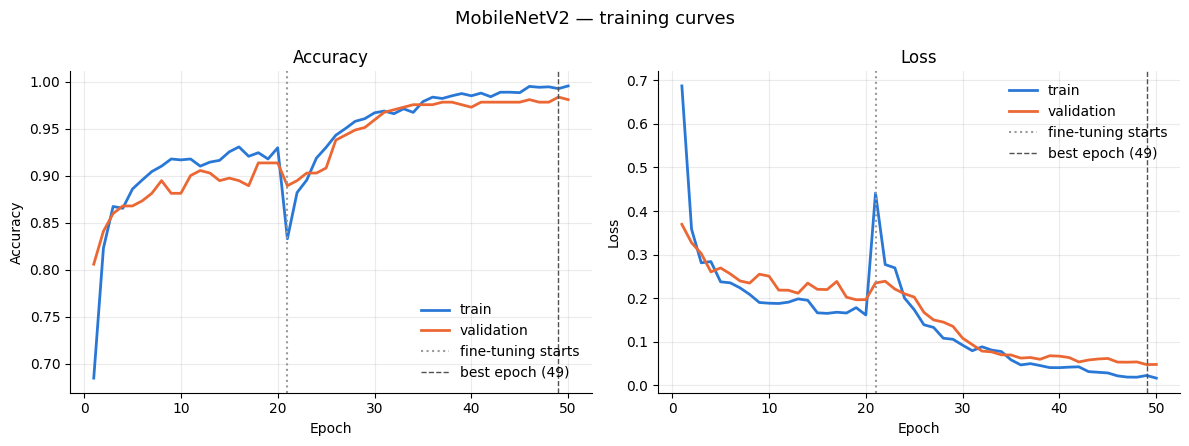

Best epoch 49: train acc 0.9928 | val acc 0.9838 | train loss 0.0226 | val loss 0.0476
Train–val accuracy gap: +0.0090  (large positive = overfitting)


In [11]:
def plot_history(hist: dict, title: str, save_path: Path):
    # Accuracy and loss curves (train vs validation) with the fine-tune start and best epoch marked.
    epochs = np.arange(1, len(hist["loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    for ax, metric, label in [(axes[0], "accuracy", "Accuracy"), (axes[1], "loss", "Loss")]:
        ax.plot(epochs, hist[metric], color=COLORS["train"], lw=2, label="train")
        ax.plot(epochs, hist[f"val_{metric}"], color=COLORS["val"], lw=2, label="validation")
        ax.axvline(hist["fine_tune_start"], color="#9a9a96", ls=":", lw=1.5, label="fine-tuning starts")
        ax.axvline(hist["best_epoch"], color="#52514e", ls="--", lw=1, label=f"best epoch ({hist['best_epoch']})")
        ax.set_xlabel("Epoch"); ax.set_ylabel(label); ax.set_title(label)
        ax.spines[["top", "right"]].set_visible(False)
        ax.grid(alpha=0.25)
        ax.legend(frameon=False)
    fig.suptitle(title, fontsize=13)
    fig.tight_layout()
    fig.savefig(save_path, dpi=150)
    plt.show()


plot_history(mnv2_hist, "MobileNetV2 — training curves", RESULTS_DIR / "02b_mobilenetv2_curves.png")

b = mnv2_hist["best_epoch"] - 1
print(f"Best epoch {b + 1}: train acc {mnv2_hist['accuracy'][b]:.4f} | val acc {mnv2_hist['val_accuracy'][b]:.4f} "
      f"| train loss {mnv2_hist['loss'][b]:.4f} | val loss {mnv2_hist['val_loss'][b]:.4f}")
print(f"Train–val accuracy gap: {mnv2_hist['accuracy'][b] - mnv2_hist['val_accuracy'][b]:+.4f}  (large positive = overfitting)")

## 11. Verify the saved model

Reload `mobilenetv2.keras` **from disk** and evaluate on the validation set — the numbers must match the best epoch above. This proves the file is complete and self-contained (augmentation, rescaling and the MobileNetV2 base are all inside it).

In [12]:
reloaded = keras.models.load_model(SAVED_DIR / f"{MODEL_NAME}.keras")
val_loss, val_acc = reloaded.evaluate(val_ds, verbose=0)
print(f"Reloaded {MODEL_NAME}.keras -> val loss {val_loss:.4f} | val accuracy {val_acc:.4f}")
print(f"File size: {(SAVED_DIR / f'{MODEL_NAME}.keras').stat().st_size / 1e6:.2f} MB | parameters: {reloaded.count_params():,}")

Reloaded mobilenetv2.keras -> val loss 0.0476 | val accuracy 0.9838
File size: 24.63 MB | parameters: 2,263,108


## 12. Summary — Part B

- A **MobileNetV2** model pre-trained on ImageNet was adapted to our 4 classes in two phases: (1) train a new head on frozen features, (2) fine-tune the top layers with a 100× smaller learning rate.
- The best model across both phases is saved at `model/saved_models/mobilenetv2.keras`, its history at `model/artifacts/history_mobilenetv2.json`, its curves at `model/results/02b_mobilenetv2_curves.png`.

**Next → `03_model_evaluation.ipynb`:** evaluate **both** models on the untouched **test set** (accuracy, precision, recall, F1, confusion matrices, CPU speed) and choose the model to deploy.